# Assignment 5: Computational Inference and Model-Based EDA

**Student names:** Alexeyenko Artyom and Akparov Dilshat  
**Student IDs:** 37463 and 37341  
**Course:** Exploratory Data Analysis  
**Assignment:** 5  
**Dataset:** `BankChurners.csv`  
**Dataset source:** [Credit Card Customers on Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)

This notebook continues Assignments 1–4, using the same customer records. It develops uncertainty intervals, a randomization test, a multiple regression and diagnostics. Tables, figures and interpretations are kept together. Run all cells from the directory containing the CSV. Required packages: `numpy pandas matplotlib seaborn scipy scikit-learn statsmodels ipython`.

## 0. Continuity and analytical choices

Assignments 1–4 showed that transaction amount and credit limit are right-skewed, transaction count and amount are strongly associated, and income groups are unequal. Unusual observations were retained as plausible. This motivates bootstrap uncertainty, a permutation test that does not assume normally distributed spending, and regression diagnostics rather than automatic deletion of extremes.

**Dataset mismatch in the assignment:** the specification mentions house values in high- and low-income groups, but also requires the previous dataset. BankChurners contains no house-value variable. We retain the required dataset and use `Total_Trans_Amt` (annual credit-card transaction amount, in USD) as the outcome. Low income means `Less than $40K`; high means `$120K +`. These are the two extreme *recorded categories*, chosen before testing; they are not individual incomes. The result concerns card spending, not housing.

All analyses are observational. A test or regression association does not establish causation. In particular, annual transaction count and amount cover overlapping periods, so their association is not necessarily a prospective prediction.

In [1]:
from pathlib import Path
import hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown

SEED = 42
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .2})
pd.set_option('display.max_columns', 20)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__, '| sklearn', sklearn.__version__, '| statsmodels', sm.__version__)
path = Path('BankChurners.csv')
df = pd.read_csv(path)
print('SHA-256:', hashlib.sha256(path.read_bytes()).hexdigest())
assert df.shape == (10127, 23) and df.CLIENTNUM.is_unique
assert not df.duplicated().any() and not df.isna().any().any()
print(f'{len(df):,} customers, {df.shape[1]} columns; {df.isna().sum().sum()} missing cells; {df.duplicated().sum()} duplicate rows.')

Python 3.15.2 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | sklearn 1.9.1 | statsmodels 0.15.0
SHA-256: c91b525a2a6755a1b0b80dad1d0d008ca97ec4df34552c8f47ffa12b6184b779
10,127 customers, 23 columns; 0 missing cells; 0 duplicate rows.


## 1. Initial exploration

Each row is a customer. `Unknown` is an explicitly recorded category, not a technical null or a numerical income. We retain it in overall analyses, and exclude it only from the pre-specified extreme-income contrast. Customer ID and the two provided Naive Bayes classifier columns are excluded from analysis: identifiers carry no measurement and classifier outputs can leak information about attrition. Monetary outliers are kept; we examine their influence later.

In [2]:
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'non-null': df.notna().sum(), 'unique': df.nunique()}))
features = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Credit_Limit', 'Avg_Utilization_Ratio', 'Customer_Age', 'Months_on_book']
display(df[features].describe().T.assign(median=df[features].median(), skew=df[features].skew()).round(2))
display(df['Income_Category'].value_counts().rename_axis('Income category').to_frame('n'))
print('Explicit Unknown values:', {c: int(df[c].eq('Unknown').sum()) for c in ['Education_Level', 'Marital_Status', 'Income_Category']})

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


,dtype,non-null,unique
CLIENTNUM,int64,10127,10127
Attrition_Flag,str,10127,2
Customer_Age,int64,10127,45
Gender,str,10127,2
Dependent_count,int64,10127,6
Education_Level,str,10127,7
Marital_Status,str,10127,4
Income_Category,str,10127,6
Card_Category,str,10127,4
Months_on_book,int64,10127,44


,count,mean,std,min,25%,50%,75%,max,median,skew
Total_Trans_Amt,10127.0,4404.09,3397.13,510.0,2155.50,3899.00,4741.0,18484.0,3899.00,2.04
Total_Trans_Ct,10127.0,64.86,23.47,10.0,45.00,67.00,81.0,139.0,67.00,0.15
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.5,34516.0,4549.00,1.67
Avg_Utilization_Ratio,10127.0,0.27,0.28,0.0,0.02,0.18,0.5,1.0,0.18,0.72
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.0,73.0,46.00,-0.03
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.0,56.0,36.00,-0.11


,n
Income category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
Unknown,1112
$120K +,727


Explicit Unknown values: {'Education_Level': 1519, 'Marital_Status': 749, 'Income_Category': 1112}


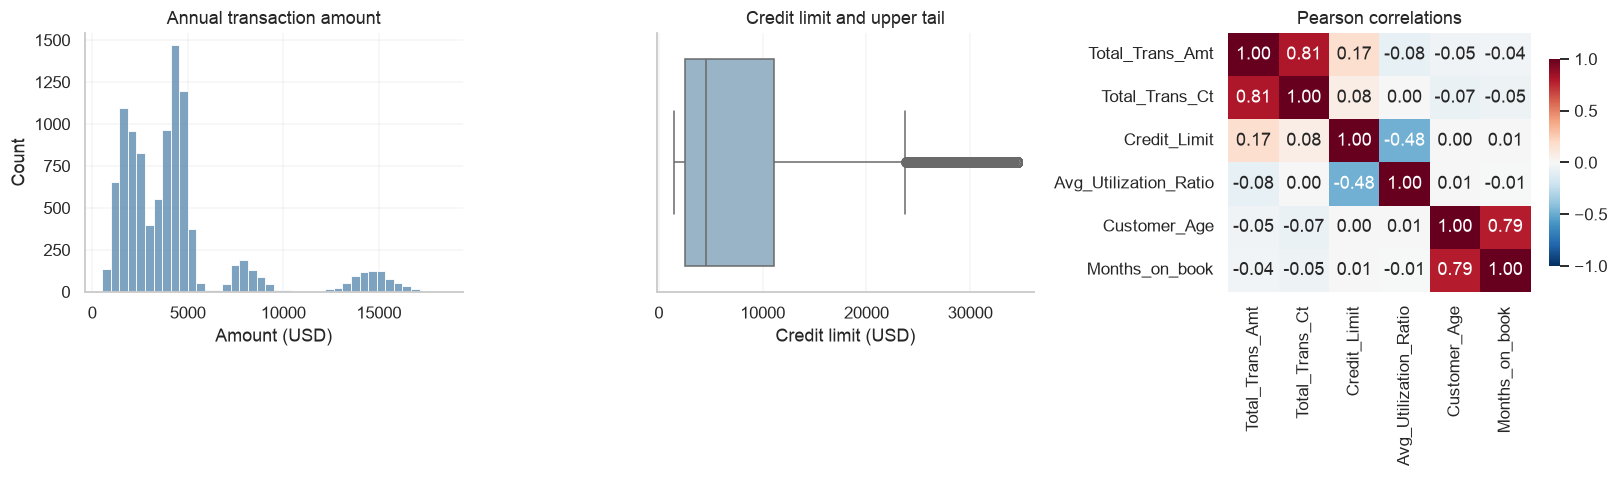

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(df['Total_Trans_Amt'], bins=40, ax=ax[0], color='#5185ad')
ax[0].set(title='Annual transaction amount', xlabel='Amount (USD)')
sns.boxplot(x=df['Credit_Limit'], ax=ax[1], color='#91b4cf')
ax[1].set(title='Credit limit and upper tail', xlabel='Credit limit (USD)')
sns.heatmap(df[features].corr(), vmin=-1, vmax=1, center=0, cmap='RdBu_r', annot=True, fmt='.2f', ax=ax[2], cbar_kws={'shrink': .8})
ax[2].set_title('Pearson correlations')
fig.tight_layout(); plt.show()

**Reading the initial views.** The spending and credit-limit distributions have long upper tails. Pearson correlations summarize linear association and may hide nonlinear patterns. Transaction amount and count are closely related partly because total spending accumulates over transactions; age and account tenure are also strongly related. These features motivate checking residual shape and multicollinearity. A high credit limit or amount is not automatically an error.

## 2. Bootstrap: uncertainty in the mean transaction amount

**Estimand:** the population mean annual transaction amount under an interpretation in which these customer records represent independent draws from a relevant population. The point estimate is the sample mean. We draw **2,000** bootstrap samples of size 10,127 with replacement and compute one mean per sample. The percentile interval is the 2.5th and 97.5th percentiles of those means. This approximates sampling uncertainty, not the range containing 95% of individual customers. It does not correct a biased or nonrepresentative sample, dependence between customers, or measurement error. The fixed seed makes Monte Carlo results reproducible.

Observed mean: $4,404.09; bootstrap SE: $33.57
95% percentile bootstrap CI: [$4,338.68, $4,470.73]; B = 2,000


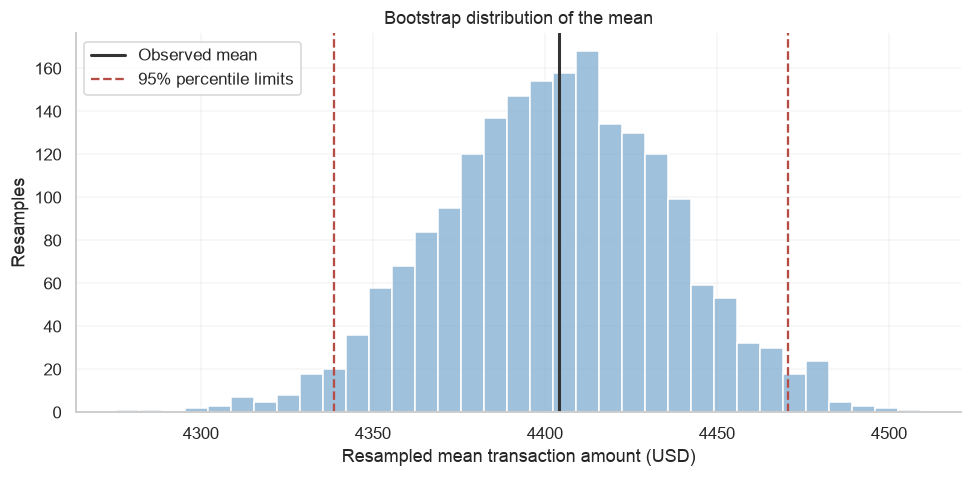

**Interpretation.** The estimated mean is **$4,404.09**, with a 95% percentile bootstrap interval of **[$4,338.68, $4,470.73]**. In repeated comparable sampling, this procedure is designed to cover the population mean about 95% of the time, subject to its assumptions. The observed interval is not a probability statement about the fixed population mean.

In [4]:
rng_boot = np.random.default_rng(SEED)
y = df['Total_Trans_Amt'].to_numpy()
B = 2000
boot_means = np.array([rng_boot.choice(y, size=len(y), replace=True).mean() for _ in range(B)])
mean_y = y.mean()
ci_lo, ci_hi = np.percentile(boot_means, [2.5, 97.5])
se_boot = boot_means.std(ddof=1)
print(f'Observed mean: ${mean_y:,.2f}; bootstrap SE: ${se_boot:,.2f}')
print(f'95% percentile bootstrap CI: [${ci_lo:,.2f}, ${ci_hi:,.2f}]; B = {B:,}')
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(boot_means, bins=35, color='#80add0', ax=ax)
ax.axvline(mean_y, color='#333333', lw=2, label='Observed mean')
ax.axvline(ci_lo, color='#b64d45', ls='--', label='95% percentile limits')
ax.axvline(ci_hi, color='#b64d45', ls='--')
ax.set(title='Bootstrap distribution of the mean', xlabel='Resampled mean transaction amount (USD)', ylabel='Resamples')
ax.legend(); fig.tight_layout(); plt.show()
display(Markdown(f'**Interpretation.** The estimated mean is **${mean_y:,.2f}**, with a 95% percentile bootstrap interval of **[${ci_lo:,.2f}, ${ci_hi:,.2f}]**. In repeated comparable sampling, this procedure is designed to cover the population mean about 95% of the time, subject to its assumptions. The observed interval is not a probability statement about the fixed population mean.'))

### 2.1 How to read the bootstrap result

A bootstrap sample is constructed by drawing 10,127 customer rows independently **with replacement** from the original file. Consequently, some original customers appear several times in a resample and others do not appear at all. We calculate the mean of each resample; the resulting 2,000 means approximate how the sample mean might vary across repeated samples from a population resembling the observed data. The empirical standard deviation of those 2,000 means, **\$33.57**, is the bootstrap standard error. It measures uncertainty in the *estimated mean*, not variability between individual customers.

The observed 95% percentile interval, **\$4,338.68–\$4,470.73**, is approximately \$132 wide and lies around the observed mean of \$4,404.09. The histogram shows the resampled means concentrated around that estimate. It is narrower than the distribution of individual spending because averaging over many customers reduces sampling variability; it should not be used as a prediction interval for an individual customer. The original spending distribution is right-skewed, so the mean remains sensitive to high spending values even though the bootstrap distribution of means is relatively concentrated.

The 2,000 repetitions satisfy the assignment and give an approximate interval: another seed can change the endpoints slightly because the simulation is finite. The percentile method is one bootstrap interval construction, not a guarantee of exact coverage in every dataset. A more representative sampling design and, where relevant, resampling clusters rather than individual rows would be needed if customers were dependent within households or other groups.

## 3. Permutation test: spending in high- and low-income categories

We compare mean annual transaction amounts in the two extreme recorded income categories. The statistic is **high-income mean minus low-income mean**; positive values mean higher observed spending in the high-income group. The null is that the two groups have the same spending distribution, making group labels exchangeable under the null. The two-sided alternative is a difference in either direction. This is stronger than merely assuming equal means when distributions differ. We randomly permute labels 20,000 times, maintaining group sizes, and estimate the two-sided p-value with the `(extreme + 1)/(permutations + 1)` correction. Income was not randomly assigned: this tests association, not an effect of increasing income. We report group sizes, medians and standard deviations because means alone conceal shape and unequal variability.

Groups exclude intermediate and Unknown income categories.


,count,mean,std,25%,50%,75%
Low: < $40K,3561.0,4363.42,3097.40,2398.0,4099.0,4751.0
High: $120K+,727.0,4529.47,3816.05,1870.5,3643.0,4831.5


Observed high − low: $166.05; |null statistic| >= observed: 4,232/20,000
Two-sided permutation p-value (plus-one): 0.211639; Monte Carlo resolution: 0.000050


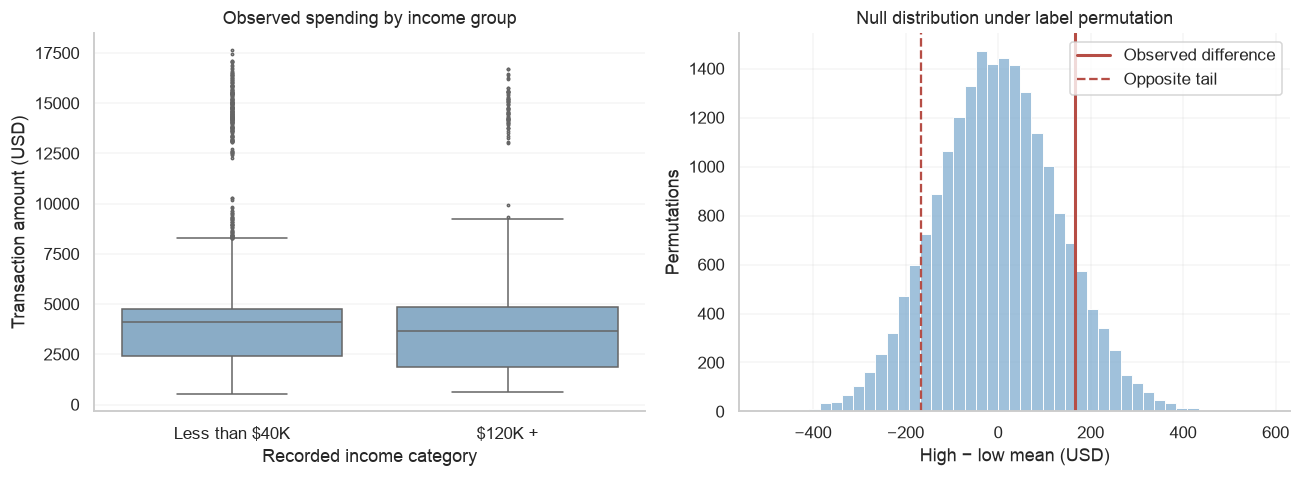

**Interpretation.** The observed high-minus-low mean difference is **$166.05** (high n=727, low n=3,561); the two-sided p-value is **0.21164**. At α = 0.05, we do not reject the exchangeable-distributions null. This p-value is the probability, under that null and randomization scheme, of a statistic at least this extreme; it is not the probability that the null is true. Statistical significance does not measure the size or practical importance of the difference.

In [5]:
low = df.loc[df['Income_Category'].eq('Less than $40K'), 'Total_Trans_Amt'].to_numpy()
high = df.loc[df['Income_Category'].eq('$120K +'), 'Total_Trans_Amt'].to_numpy()
assert len(low) and len(high)
group_stats = pd.DataFrame({'Low: < $40K': pd.Series(low).describe(), 'High: $120K+': pd.Series(high).describe()}).T
print('Groups exclude intermediate and Unknown income categories.')
display(group_stats[['count','mean','std','25%','50%','75%']].round(2))
observed = high.mean() - low.mean()
pooled = np.concatenate([high, low]); n_high = len(high)
rng_perm = np.random.default_rng(SEED + 1)
R = 20000
permuted = np.empty(R)
for i in range(R):
    shuffled = rng_perm.permutation(pooled)
    permuted[i] = shuffled[:n_high].mean() - shuffled[n_high:].mean()
extreme = np.count_nonzero(np.abs(permuted) >= abs(observed))
p_perm = (extreme + 1) / (R + 1)
print(f'Observed high − low: ${observed:,.2f}; |null statistic| >= observed: {extreme:,}/{R:,}')
print(f'Two-sided permutation p-value (plus-one): {p_perm:.6f}; Monte Carlo resolution: {1/(R+1):.6f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df[df['Income_Category'].isin(['Less than $40K', '$120K +'])], x='Income_Category', y='Total_Trans_Amt', order=['Less than $40K', '$120K +'], ax=ax[0], color='#80add0', fliersize=1.5)
ax[0].set(title='Observed spending by income group', xlabel='Recorded income category', ylabel='Transaction amount (USD)')
sns.histplot(permuted, bins=45, ax=ax[1], color='#80add0')
ax[1].axvline(observed, color='#b64d45', lw=2, label='Observed difference')
ax[1].axvline(-observed, color='#b64d45', ls='--', label='Opposite tail')
ax[1].set(title='Null distribution under label permutation', xlabel='High − low mean (USD)', ylabel='Permutations')
ax[1].legend(); fig.tight_layout(); plt.show()
display(Markdown(f'**Interpretation.** The observed high-minus-low mean difference is **${observed:,.2f}** (high n={len(high):,}, low n={len(low):,}); the two-sided p-value is **{p_perm:.5f}**. At α = 0.05, we {"reject" if p_perm < .05 else "do not reject"} the exchangeable-distributions null. This p-value is the probability, under that null and randomization scheme, of a statistic at least this extreme; it is not the probability that the null is true. Statistical significance does not measure the size or practical importance of the difference.'))

### 3.1 What the test tells us about the two groups

The low-income group contains **3,561** customers and has a mean of **\$4,363.42**; the high-income group contains **727** customers and has a mean of **\$4,529.47**. The observed difference of **+\$166.05** is approximately **3.8% of the low-income mean**. However, the high-income group has a *lower median* (\$3,643 versus \$4,099) and a larger standard deviation (\$3,816.05 versus \$3,097.40). Thus a higher mean does not imply that a typical high-income customer spends more: the two summaries capture different parts of the distributions, and the mean is sensitive to the upper tail. The groups are unequal in size, so their estimates have different precision.

Under the null of identical spending distributions, we pool the two samples, redistribute their income labels while retaining their original group sizes, and recompute the difference. Of 20,000 simulated differences, **4,232** were at least as extreme in absolute value as the observed difference. Including the observed arrangement through the plus-one correction yields **p ≈ 0.212**. At the stated 5% threshold this is not sufficient evidence against the exchangeability null. It does **not** establish that the groups are identical or that the true mean difference is zero; a confidence interval for the difference or a study designed for equivalence would address different questions.

The test compares only the two chosen income categories. `Unknown` and intermediate categories are not assigned to either group, so this result should not be generalized automatically to all income levels. Moreover, the unadjusted comparison does not account for other differences between customers, such as card use or financial characteristics. If group distributions differ in shape or spread, the unstudentized label-permutation test should not be interpreted as an exact test of *equal means alone*.

## 4. Multiple linear regression

**Question:** how well can annual transaction amount be summarized by transaction count, credit limit, age, and account tenure together? We use ordinary least squares with an intercept. These numerical predictors were chosen to cover activity, financial capacity, and life-cycle characteristics while avoiding derived balance/limit variables and prior classifier outputs. Count and amount measure the same period: the model is descriptive and should not be called an early-warning forecast. We do not include attrition status, which could reflect the same period as the outcome.

We split customers **80% training / 20% test**, randomly with seed 42, before fitting; all 10,127 rows are retained. No feature selection or tuning is performed on the test set. We report train and held-out MAE and RMSE in USD and R². MAE is the average absolute prediction error; RMSE gives greater weight to large misses; R² compares squared error with a constant equal to the evaluation set's mean and may be negative. The test R² baseline uses the test mean for the definition, not as a deployable prediction. A random split evaluates similar records, not future or external customers.

In [6]:
predictors = ['Total_Trans_Ct', 'Credit_Limit', 'Customer_Age', 'Months_on_book']
X_train, X_test, y_train, y_test = train_test_split(df[predictors], df['Total_Trans_Amt'], test_size=.2, random_state=SEED)
reg = LinearRegression().fit(X_train, y_train)
train_pred, test_pred = reg.predict(X_train), reg.predict(X_test)
def metrics(actual, predicted):
    return {'n': len(actual), 'MAE (USD)': mean_absolute_error(actual, predicted),
            'RMSE (USD)': np.sqrt(mean_squared_error(actual, predicted)), 'R²': r2_score(actual, predicted)}
performance = pd.DataFrame({'Train': metrics(y_train, train_pred), 'Test': metrics(y_test, test_pred)}).T
print('Model evaluation:'); display(performance.round(3))
coefs = pd.Series(np.r_[reg.intercept_, reg.coef_], index=['Intercept'] + predictors, name='OLS coefficient (USD)').to_frame()
display(coefs.round(3))
display(Markdown(f'**Interpretation.** Held-out MAE is **${performance.loc["Test", "MAE (USD)"]:,.0f}**, RMSE is **${performance.loc["Test", "RMSE (USD)"]:,.0f}**, and R² is **{performance.loc["Test", "R²"]:.3f}**. RMSE being larger than MAE signals that larger misses matter. Each slope is a conditional linear association holding the other listed predictors fixed; it is not a causal effect. The intercept describes a zero-predictor combination and has limited practical meaning.'))

Model evaluation:


,n,MAE (USD),RMSE (USD),R²
Train,8101.0,1452.449,1970.054,0.665
Test,2026.0,1432.124,1966.141,0.661


,OLS coefficient (USD)
Intercept,-3634.189
Total_Trans_Ct,115.534
Credit_Limit,0.041
Customer_Age,8.772
Months_on_book,-6.210


**Interpretation.** Held-out MAE is **$1,432**, RMSE is **$1,966**, and R² is **0.661**. RMSE being larger than MAE signals that larger misses matter. Each slope is a conditional linear association holding the other listed predictors fixed; it is not a causal effect. The intercept describes a zero-predictor combination and has limited practical meaning.

### 4.1 Model, coefficients and evaluation in context

The fitted relationship has the form **predicted amount = intercept + b₁ × transaction count + b₂ × credit limit + b₃ × age + b₄ × tenure**. Ordinary least squares chooses coefficients that minimize the sum of squared training residuals. Predictions and errors are in USD; transaction count is a count, credit limit is in USD, age is in years and tenure is in months. The intercept is approximately **−\$3,634**, but an observation with all four predictors equal to zero is outside the useful context of these data, so the intercept is mainly needed to position the fitted line.

With the other listed predictors held fixed, one additional transaction is associated with approximately **\$115.53** greater fitted annual amount. A **\$1,000** higher credit limit corresponds to about **\$41** greater fitted amount; one extra year of age corresponds to about **\$8.77**, while one extra month of tenure corresponds to about **−\$6.21**. These are conditional associations within the fitted linear model, not effects of interventions. Age and tenure are correlated, which can make their separate coefficients less stable; count and total amount are also related by construction. The analysis does not establish coefficient significance or causal direction.

The model has **8,101 training** and **2,026 test** records. Training MAE/RMSE are approximately **\$1,452/\$1,970**, compared with **\$1,432/\$1,966** on the test set; R² is **0.665** on training and **0.661** on test. The small gap suggests no obvious deterioration on this particular random split, but a single split cannot establish stability or performance on future data. On the test set, R² of 0.661 means that squared error is approximately **66.1% lower** than using the test-set mean as a constant benchmark. The remaining error is substantial relative to the overall mean spending of about \$4,404. RMSE exceeds MAE because larger misses receive more weight, making residual diagnostics and influence analysis in Section 5 essential.

## 5. Model diagnostics

We inspect **held-out** residuals (actual minus predicted) against predictions and assess their distribution. Diagnostics such as the Breusch–Pagan test, influence and VIF use the **training fit** only. A well-specified linear conditional mean should have no systematic residual pattern; constant variance means similar vertical spread over the fitted range. A Q–Q plot assesses the shape of residuals, not the normality of predictors. Normal errors are not required to compute OLS or held-out metrics, but non-normality affects small-sample classical inference. Independent records are assumed; the file alone cannot establish independence or time ordering.

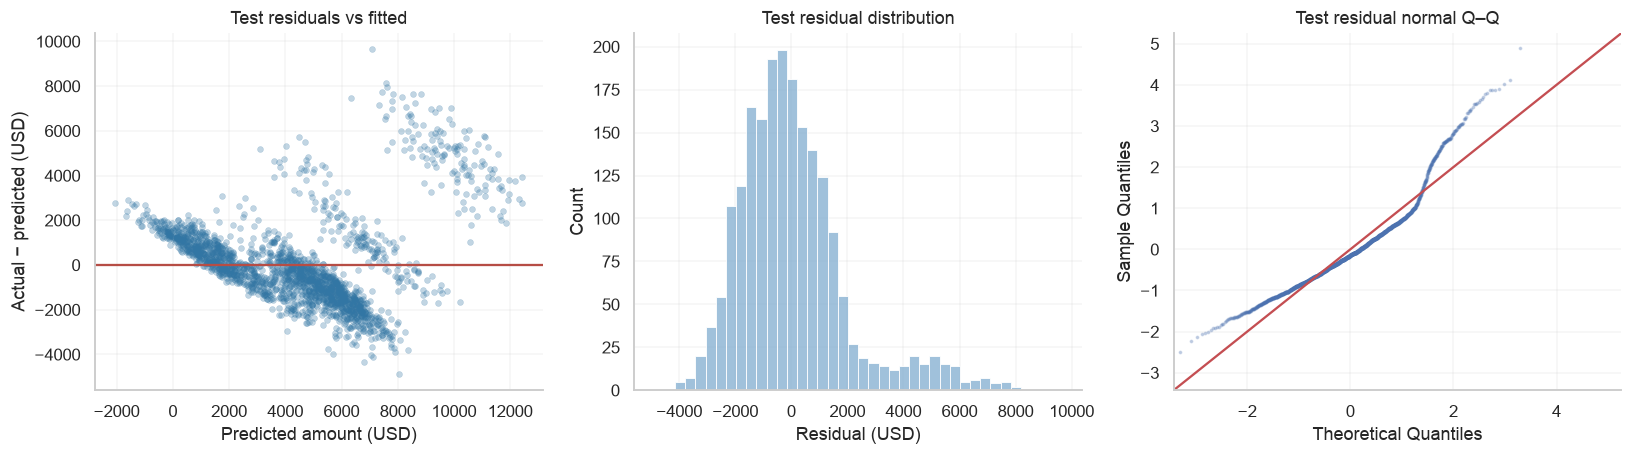

,n,mean,sd,median
fitted quintile,,,,
"(-2046.081, 1607.13]",406,1022.27,611.34,1021.44
"(1607.13, 3898.026]",405,-82.52,944.12,-174.75
"(3898.026, 5210.847]",405,-474.84,1317.35,-610.45
"(5210.847, 6476.745]",405,-1075.19,1377.40,-1326.21
"(6476.745, 12433.657]",405,778.22,3382.04,-54.82


In [7]:
test_resid = y_test.to_numpy() - test_pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
sns.scatterplot(x=test_pred, y=test_resid, s=15, alpha=.3, ax=ax[0], color='#3276a4', edgecolor=None)
ax[0].axhline(0, color='#b64d45', lw=1.5); ax[0].set(title='Test residuals vs fitted', xlabel='Predicted amount (USD)', ylabel='Actual − predicted (USD)')
sns.histplot(test_resid, bins=40, ax=ax[1], color='#80add0'); ax[1].set(title='Test residual distribution', xlabel='Residual (USD)')
sm.qqplot(test_resid, line='45', fit=True, ax=ax[2], marker='.', alpha=.25, markersize=3); ax[2].set_title('Test residual normal Q–Q')
fig.tight_layout(); plt.show()
resid_bins = pd.DataFrame({'fitted': test_pred, 'residual': test_resid})
resid_bins['fitted quintile'] = pd.qcut(resid_bins['fitted'], 5, duplicates='drop')
display(resid_bins.groupby('fitted quintile', observed=True)['residual'].agg(n='size', mean='mean', sd='std', median='median').round(2))

**Diagnostic reading.** The held-out residuals form structured bands rather than a random horizontal cloud. The mean residual shifts from about +$1,022 in the lowest fitted quintile to −$1,075 in the fourth; the highest quintile has a large positive tail. Residual SD rises from about $611 in the lowest quintile to $3,382 in the highest. The Q–Q plot departs strongly from the line in the upper tail. These patterns suggest nonlinearity or omitted structure, unequal variance, and non-normal residuals; the model also produces some negative predictions for a positive outcome. The held-out score therefore does not make the straight-line model adequate in every region.

In [8]:
Xtr_const = sm.add_constant(X_train, has_constant='add')
ols = sm.OLS(y_train, Xtr_const).fit()
assert np.allclose(ols.predict(Xtr_const), train_pred)
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(ols.resid, Xtr_const)
print(f'Breusch–Pagan LM = {bp_lm:.3f}, p = {bp_p:.3g}; F = {bp_f:.3f}, p = {bp_fp:.3g} (0 indicates numerical underflow)')
print('Null: residual variance does not depend linearly on the supplied predictors.')
vif = pd.DataFrame({'Predictor': predictors, 'VIF': [variance_inflation_factor(Xtr_const.to_numpy(), i) for i in range(1, len(predictors)+1)]})
display(vif.round(2))
influence = ols.get_influence()
cooks = influence.cooks_distance[0]
student = influence.resid_studentized_internal
leverage = influence.hat_matrix_diag
threshold = 4 / len(X_train)
diagnostic = pd.DataFrame({'row index': X_train.index, 'actual': y_train.to_numpy(), 'fitted': train_pred, 'residual': ols.resid.to_numpy(), 'studentized residual': student, 'leverage': leverage, 'Cook D': cooks})
print(f'Cook D > 4/n ({threshold:.6f}): {(cooks > threshold).sum()} training records; |studentized residual| > 3: {(np.abs(student)>3).sum()}')
display(diagnostic.nlargest(8, 'Cook D').round(3))
display(Markdown(f'**Heteroscedasticity.** The Breusch–Pagan p-value is **{'< 1e-300' if bp_p == 0 else format(bp_p, '.3g')}**, so at 5% we {"reject" if bp_p < .05 else "do not reject"} constant variance against its specified alternative. With a large sample, even modest departures can be significant; inspect the residual plot and quintile SDs for magnitude. Misspecified conditional mean or non-independent records can also affect the test. **Multicollinearity.** The maximum training VIF is **{vif.VIF.max():.2f}**. VIF describes inflation of coefficient variance from linear dependence on the other predictors; it does not diagnose all nonlinear dependence. Thresholds such as 5 or 10 are screening conventions, not hard rules.'))

Breusch–Pagan LM = 1824.736, p = 0; F = 588.450, p = 0 (0 indicates numerical underflow)
Null: residual variance does not depend linearly on the supplied predictors.


,Predictor,VIF
0,Total_Trans_Ct,1.01
1,Credit_Limit,1.01
2,Customer_Age,2.69
3,Months_on_book,2.69


Cook D > 4/n (0.000494): 701 training records; |studentized residual| > 3: 142


,row index,actual,fitted,residual,studentized residual,leverage,Cook D
6678,9745,15925,8144.768,7780.232,3.951,0.001,0.005
6857,10028,17437,9887.965,7549.035,3.834,0.002,0.005
4852,9934,16258,10236.609,6021.391,3.059,0.002,0.004
2103,9472,14080,6388.656,7691.344,3.905,0.001,0.004
5383,10097,17744,8682.721,9061.279,4.600,0.001,0.004
4058,9873,14954,8945.051,6008.949,3.052,0.002,0.004
7796,9928,16236,7539.052,8696.948,4.415,0.001,0.003
4291,9235,17064,10067.657,6996.343,3.553,0.001,0.003


**Heteroscedasticity.** The Breusch–Pagan p-value is **< 1e-300**, so at 5% we reject constant variance against its specified alternative. With a large sample, even modest departures can be significant; inspect the residual plot and quintile SDs for magnitude. Misspecified conditional mean or non-independent records can also affect the test. **Multicollinearity.** The maximum training VIF is **2.69**. VIF describes inflation of coefficient variance from linear dependence on the other predictors; it does not diagnose all nonlinear dependence. Thresholds such as 5 or 10 are screening conventions, not hard rules.

### 5.1 Influence and sensitivity

A large residual is an unusual outcome conditional on the model; high leverage means an unusual predictor combination; Cook's distance combines residual size and leverage to flag observations that may change the fitted coefficients. The 4/n cutoff is a screening rule, not proof of error. We retain all customers in the primary model. As a sensitivity check only, refit on the training set after removing flagged rows, then evaluate both models on the **same untouched test set**. This is not an instruction to discard valid customers, and the data-dependent removal can itself bias the fit. Compare slopes and held-out errors rather than interpreting flags as mistakes.

In [9]:
keep = cooks <= threshold
sensitivity = LinearRegression().fit(X_train.loc[keep], y_train.loc[keep])
sens_pred = sensitivity.predict(X_test)
sens_metrics = pd.DataFrame({'All training records': metrics(y_test, test_pred), 'Without flagged training records': metrics(y_test, sens_pred)}).T
display(sens_metrics.round(3))
display(pd.DataFrame({'All training records': reg.coef_, 'Without flagged': sensitivity.coef_}, index=predictors).round(3))
print(f'Sensitivity refit retained {keep.sum():,}/{len(keep):,} training records; all {len(y_test):,} test records were evaluated.')
assert len(X_train) + len(X_test) == len(df) and len(boot_means) == 2000 and len(permuted) == 20000

,n,MAE (USD),RMSE (USD),R²
All training records,2026.0,1432.124,1966.141,0.661
Without flagged training records,2026.0,1242.888,2236.189,0.562


,All training records,Without flagged
Total_Trans_Ct,115.534,77.670
Credit_Limit,0.041,0.023
Customer_Age,8.772,8.184
Months_on_book,-6.210,-0.299


Sensitivity refit retained 7,400/8,101 training records; all 2,026 test records were evaluated.


**Sensitivity result.** Removing 701 flagged training observations lowers test MAE from about $1,432 to $1,243, but increases RMSE from $1,966 to $2,236 and reduces test R² from 0.661 to 0.562. The transaction-count slope falls from about 115.5 to 77.7 USD per transaction. Thus the refit improves the typical absolute error while worsening large errors; coefficients and conclusions are sensitive to these records. The full-data fit remains primary because influence alone does not establish that the records are erroneous.

## 6. Integrated conclusions, limitations and recommendations

1. The bootstrap distribution and 95% interval quantify uncertainty around the **mean**, while the underlying skewed individual distribution remains much wider. The interval is conditional on the sample and assumptions; it cannot repair selection bias.
2. The permutation test compares spending between the lowest and highest *recorded* income categories. Its observed difference and p-value are reported in Section 3 alongside sample sizes and distributions. Intermediate and unknown income groups are excluded from this particular contrast; income category is not an intervention.
3. The held-out metrics quantify model performance for a random split from this file. Transaction count and amount are mathematically and temporally related, so a good score is not evidence of forecasting ability or a causal effect. Comparing train and test scores helps identify, but cannot rule out, overfitting or distribution shift.
4. Residual plots, the variance test, influential-point table, and VIF each answer different questions. A statistically significant variance test need not imply a practically large problem. High influence identifies observations to investigate, not delete. The sensitivity refit illustrates how dependence on flagged cases may affect the conclusions.
5. **Limitations:** the sampling mechanism and exact timing are not established, Unknown categories remain, groups are unequal, and a random split does not test future customers. Correlated age and tenure make separate coefficients less stable. Tests and intervals assume independent, representative observations; none addresses unmeasured confounding.
6. **Recommendations:** investigate source definitions and unusual influential records with domain knowledge; compare flexible or transformed-outcome models and heteroscedasticity-robust uncertainty for coefficient inference; validate any proposed predictive use on a genuinely later, external test set with only information available at prediction time. For income comparisons, examine within-group distributions and possible confounders before drawing operational conclusions.

### Requirements and reproducibility check

| Assignment requirement | Location |
|---|---|
| Structure, descriptive statistics, distributions, correlations | Section 1 |
| 2,000 bootstrap iterations and 95% confidence interval | Section 2 |
| High–low income permutation test and p-value | Section 3; outcome adapted to the available dataset |
| Multiple regression and MAE, RMSE, R² | Section 4; train and held-out test |
| Residuals, heteroscedasticity, outliers and multicollinearity | Section 5, including sensitivity |
| Findings, limitations and recommendations | Section 6 |

The original file is never modified. Random generators and split are seeded, and package versions and CSV checksum are printed in Section 0.